<a href="https://colab.research.google.com/github/anupbagale/Neural_Network_lab/blob/main/notebooks/02_activation_functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 2: Activation Functions

Lesson 2 of 8, about 25 minutes.

After this lesson you should be able to:

1. Plot and compare step, sigmoid and ReLU activation functions.
2. Explain what the steepness parameter $\lambda$ does to a sigmoid.
3. Derive the sigmoid derivatives $\tfrac{\lambda}{2}(1-o^2)$ and $\lambda\,o(1-o)$.
4. Relate the size of the derivative to how fast a neuron learns.

You will need: lesson 1, and derivatives of exponential functions.

In [1]:
# Setup (works locally and on Google Colab)
try:
    import nnlab
except ImportError:  # not installed yet, e.g. on Colab
    %pip install -q "git+https://github.com/anupbagale/Neural_Network_lab"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## Why activation functions matter

Lesson 1 used a hard threshold. That is fine for logic gates, but it causes two problems once we
want the network to learn:

1. The step function is flat almost everywhere, so its derivative is zero and gradient-based
   learning (lessons 5 and 6) has nothing to work with.
2. Without some non-linearity, stacking layers gains nothing, because a chain of linear maps is
   still a linear map.

An activation function $f$ maps the net input to the output, $o = f(net)$. These are the ones used
in this lab:

| Name | Formula | Range |
|---|---|---|
| Bipolar step (signum) | $\operatorname{sgn}(net)$ | $\{-1, 0, 1\}$ |
| Unipolar step | $\tfrac12(\operatorname{sgn}(net) + 1)$ | $\{0, \tfrac12, 1\}$ |
| Bipolar sigmoid | $\dfrac{2}{1 + e^{-\lambda\, net}} - 1$ | $(-1, 1)$ |
| Unipolar sigmoid | $\dfrac{1}{1 + e^{-\lambda\, net}}$ | $(0, 1)$ |
| Linear | $net$ | all real numbers |
| ReLU | $\max(0, net)$ | $[0, \infty)$ |
| Leaky ReLU | $net$ if $net > 0$, else $\alpha\, net$ | all real numbers |

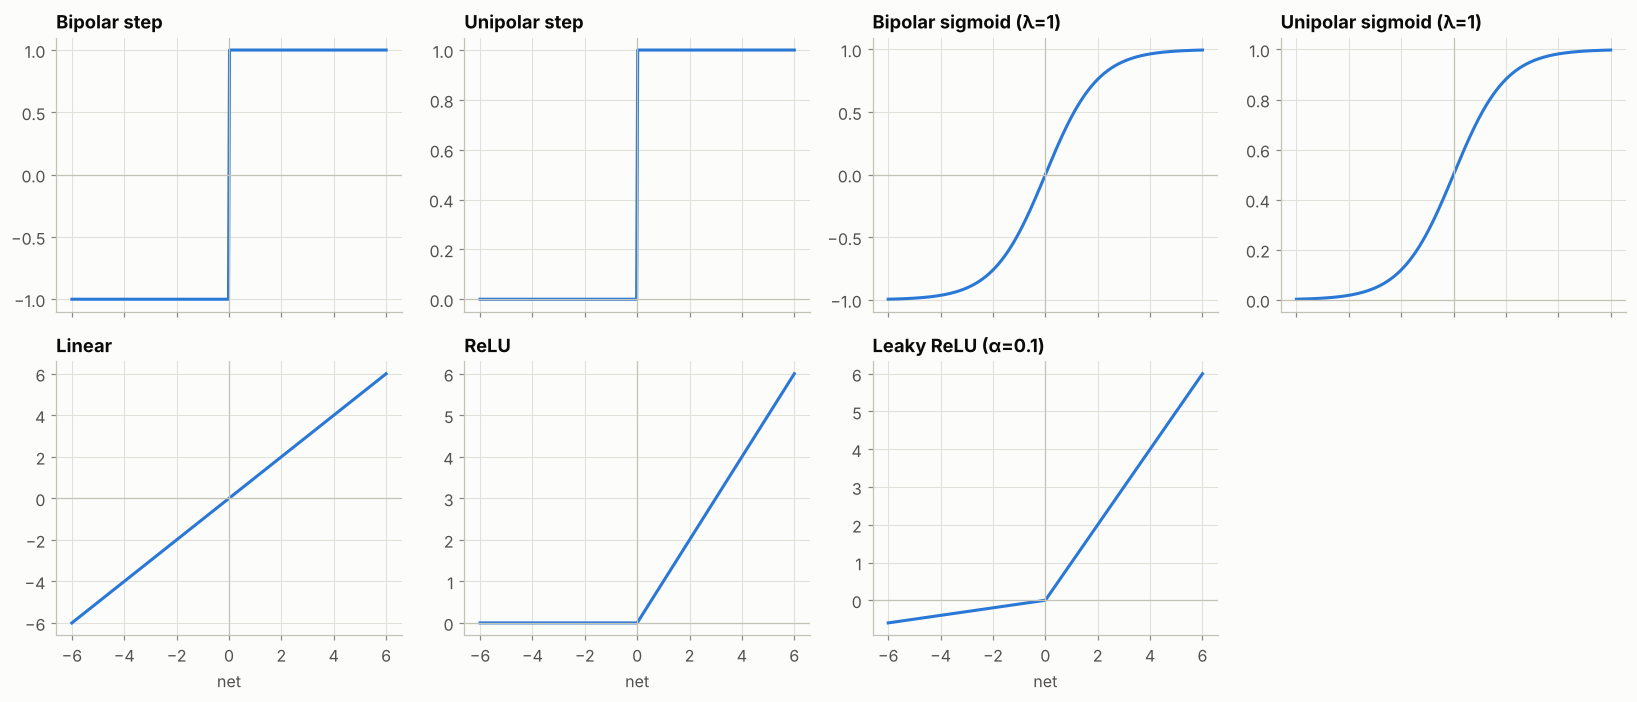

In [2]:
from nnlab import activations as act

net = np.linspace(-6, 6, 601)
functions = {
    "Bipolar step": act.bipolar_step(net),
    "Unipolar step": act.unipolar_step(net),
    "Bipolar sigmoid (λ=1)": act.bipolar_sigmoid(net),
    "Unipolar sigmoid (λ=1)": act.unipolar_sigmoid(net),
    "Linear": act.linear(net),
    "ReLU": act.relu(net),
    "Leaky ReLU (α=0.1)": act.leaky_relu(net),
}

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for ax, (name, y) in zip(axes.flat, functions.items()):
    ax.plot(net, y, color=PALETTE[0])
    ax.axhline(0, color="#c3c2b7", lw=0.8)
    ax.axvline(0, color="#c3c2b7", lw=0.8)
    ax.set_title(name)
axes.flat[-1].axis("off")
for ax in axes[1]:
    ax.set_xlabel("net")
fig.tight_layout()
plt.show()

## The steepness parameter

$\lambda$ scales the net input before it goes through the sigmoid. A small $\lambda$ gives a
gentle curve that is almost linear near zero. A large $\lambda$ gives something close to a step.
In the limit,

$$\lim_{\lambda \to \infty} \frac{2}{1 + e^{-\lambda\, net}} - 1 = \operatorname{sgn}(net).$$

A note on the first version of this notebook: it looped over $\lambda = 1, \dots, 10$ but never
used $\lambda$ inside the formula, so all ten curves were the same. That is fixed in
`nnlab.activations`, and a test checks it.

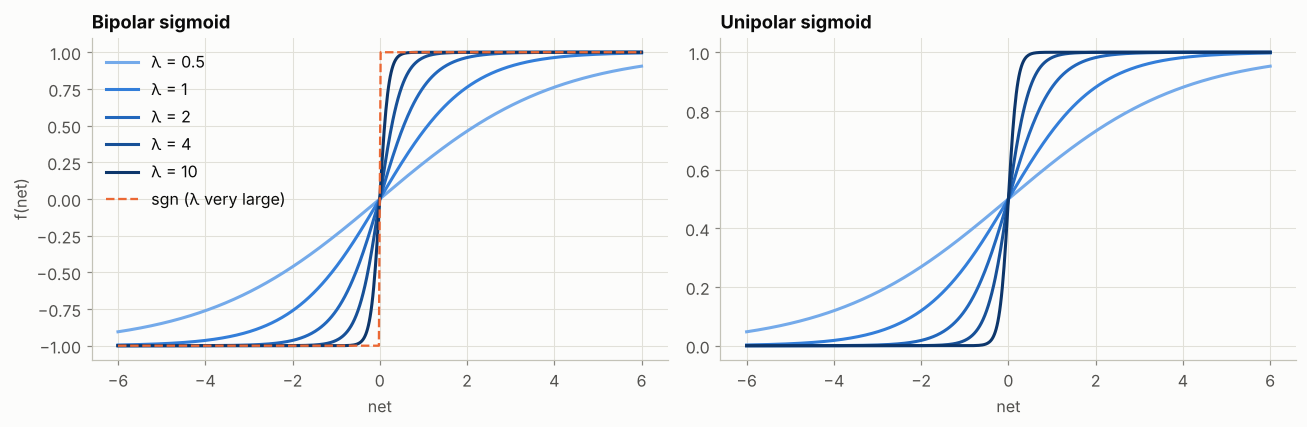

In [3]:
from matplotlib import colormaps

lambdas = [0.5, 1, 2, 4, 10]
colors = colormaps["nnlab_seq"](np.linspace(0.3, 1.0, len(lambdas)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for lam, c in zip(lambdas, colors):
    ax1.plot(net, act.bipolar_sigmoid(net, lam), color=c, label=f"λ = {lam}")
    ax2.plot(net, act.unipolar_sigmoid(net, lam), color=c, label=f"λ = {lam}")
ax1.plot(net, act.bipolar_step(net), color=PALETTE[1], ls="--", lw=1.5, label="sgn (λ very large)")
ax1.set(title="Bipolar sigmoid", xlabel="net", ylabel="f(net)")
ax2.set(title="Unipolar sigmoid", xlabel="net")
ax1.legend(loc="upper left")
fig.tight_layout()
plt.show()

## Derivatives

Gradient-based learning needs $f'(net)$. For sigmoids the derivative can be written using only the
output $o = f(net)$, which the neuron has already computed:

$$
\text{bipolar: } f'(net) = \frac{\lambda}{2}\left(1 - o^2\right), \qquad
\text{unipolar: } f'(net) = \lambda\, o\,(1 - o).
$$


**Derive the unipolar formula.**

<details><summary>Answer</summary>

With $o = (1 + e^{-\lambda net})^{-1}$,

$$f'(net) = \frac{\lambda e^{-\lambda net}}{(1 + e^{-\lambda net})^2}
= \lambda \cdot \frac{1}{1 + e^{-\lambda net}} \cdot \frac{e^{-\lambda net}}{1 + e^{-\lambda net}}
= \lambda\, o\,(1 - o).$$

The bipolar case follows from $f_{bip} = 2 f_{uni} - 1$.

</details>

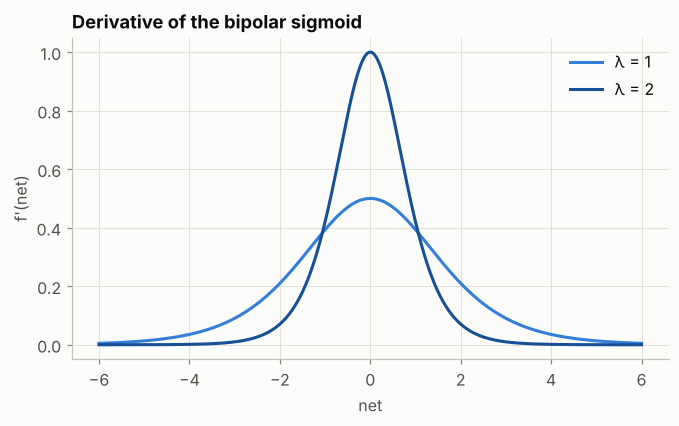

largest difference: 2.524698783368251e-10


In [4]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for lam, c in zip([1, 2, 4], colors[1::2]):
    o = act.bipolar_sigmoid(net, lam)
    ax.plot(net, act.bipolar_sigmoid_derivative(o, lam), color=c, label=f"λ = {lam}")
ax.set(title="Derivative of the bipolar sigmoid", xlabel="net", ylabel="f'(net)")
ax.legend()
plt.show()

# compare the formula with a numerical derivative
h = 1e-6
numeric = (act.bipolar_sigmoid(net + h) - act.bipolar_sigmoid(net - h)) / (2 * h)
formula = act.bipolar_sigmoid_derivative(act.bipolar_sigmoid(net))
print("largest difference:", np.max(np.abs(numeric - formula)))

The derivative is largest at $net = 0$, where it equals $\lambda/2$, and it shrinks quickly as
$|net|$ grows. A neuron whose net input is far from zero is saturated: changing its weights hardly
changes its output, so it learns slowly. In a deep network many saturated layers multiply these
small numbers together and the gradient reaching the first layers almost disappears. This is the
vanishing gradient problem.

ReLU (Nair and Hinton, 2010) has slope 1 for positive inputs, which helps. Leaky ReLU (Maas et al.,
2013) keeps a small slope $\alpha$ for negative inputs so a neuron never stops learning entirely.

## Exercises

1. Check numerically that the bipolar sigmoid equals $\tanh(\lambda\,net / 2)$.
2. What happens to the derivative curve as $\lambda \to 0$, and as $\lambda \to \infty$?
3. Plot the derivative of ReLU. Where is it undefined, and what value do libraries use there?

In [5]:
# Exercise 1
lam = 3
print(np.allclose(act.bipolar_sigmoid(net, lam), np.tanh(lam * net / 2)))

True


**Answers to exercises 2 and 3**

<details><summary>Answer</summary>

2. As $\lambda \to 0$ the derivative flattens towards zero everywhere and the neuron becomes almost linear with a tiny slope. As $\lambda \to \infty$ it turns into a tall, narrow spike at zero, which is the "derivative" of the step function.
3. The derivative of ReLU is 0 for $net < 0$ and 1 for $net > 0$. It is undefined at 0, where libraries usually just use 0.

</details>

## Summary

- Activation functions add the non-linearity that makes extra layers useful.
- λ sets how steep a sigmoid is. As λ grows the sigmoid approaches the step function.
- Sigmoid derivatives can be computed from the output: λ/2·(1 − o²) and λ·o(1 − o).
- Saturated neurons have small derivatives and learn slowly. ReLU-type functions reduce this.

Next: [Lesson 3, Hebbian Learning](03_hebbian_learning.ipynb)

### References

- Zurada, J. M. (1992). *Introduction to Artificial Neural Systems*. West Publishing Company.
- Nair, V., & Hinton, G. E. (2010). Rectified linear units improve restricted Boltzmann machines. *Proceedings of ICML*, 807–814.
- Maas, A. L., Hannun, A. Y., & Ng, A. Y. (2013). Rectifier nonlinearities improve neural network acoustic models. *ICML Workshop on Deep Learning for Audio, Speech and Language Processing*.